# 06 — CAE Transistor EXP-003 : entraînement amélioré et évaluation complète
**Projet :** IndustrialDefect AI · **EPIC-03 / EPIC-05** · suite de **EXP-002 (Mouad)**

Le benchmark US-05-03 a montré que **CAE Transistor EXP-001** détecte peu de défauts
(recall 0,15, Image-AUROC 0,586). Ce notebook reprend l'EXP-002 de Mouad
(300 époques max, `ReduceLROnPlateau`, early stopping) et compare **deux variantes**
entraînées dans les mêmes conditions :

| Variante | Perte d'entraînement | Rôle |
|---|---|---|
| **A** | MSE | EXP-002 de Mouad, telle quelle |
| **B** | MSE + 0,5 × (1 − SSIM) | Ajoute une perte **structurelle** (contours, formes) |

**Règles fixées avant l'exécution (aucune n'utilise le test) :**
1. Même architecture `cae_baseline_v1` et **même score** que l'application
   (`CAEInference` : carte MSE, lissage gaussien σ = 4, maximum) : le checkpoint reste
   compatible avec l'application et le registre.
2. **Choix du checkpoint et de la variante sur la Validation** : AUROC entre les 43 normales
   de validation et 43 copies avec **défauts synthétiques** (générateur figé, seed 2026).
   Égalité → plus faible MSE de validation.
3. **Seuil** = quantile 0,95 linéaire des scores des normales de validation, règle
   `score > seuil` (protocole US-05-02).
4. Le **test officiel** n'est chargé qu'à la fin, **une seule fois**, pour mesurer.

**Transparence :** cette expérience est décidée **après** le benchmark US-05-03 ; elle est
présentée comme une **étude complémentaire**, à côté d'EXP-001, sans remplacer
silencieusement les résultats archivés.

In [1]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

# Test local uniquement (IDL_DRY_RUN=1) : CPU, 3 époques, faux dataset. Sur Kaggle : False.
DRY_RUN = os.environ.get("IDL_DRY_RUN") == "1"

# ===== Code de l'équipe (dépôt GitHub) =====
REPO_URL = "https://github.com/MRdrissi/industrial-defect-ai.git"
REPO_BRANCH = "develop"

if DRY_RUN:
    REPO_DIR = Path(os.environ["IDL_REPO_DIR"])
else:
    REPO_DIR = Path("/kaggle/temp/industrial-defect-ai")   # non sauvegardé dans l'Output
    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)
    subprocess.run(
        ["git", "clone", "--quiet", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )
GIT_COMMIT = subprocess.run(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    capture_output=True, text=True, check=True,
).stdout.strip()
sys.path.insert(0, str(REPO_DIR))

import numpy as np
import torch
import torch.nn.functional as F
import torchvision

from src.data.dataloaders import create_dataloader
from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.evaluation.metrics import compute_image_metrics, compute_pixel_auroc
from src.inference.cae_inference import CAEInference, CAEInferenceConfig
from src.models.convolutional_autoencoder import CAEConfig, ConvolutionalAutoencoder

if DRY_RUN:
    DEVICE = torch.device("cpu")
else:
    assert torch.cuda.is_available(), "GPU non disponible : Session options → Accelerator → GPU T4 x2"
    DEVICE = torch.device("cuda")

print("Branche     :", REPO_BRANCH)
print("Commit      :", GIT_COMMIT)
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__, "| torchvision :", torchvision.__version__)
print("Matériel    :", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (test local)")

Branche     : develop
Commit      : 0e102a07e220724f7fb7d82fd9efa94e3cad52b2
Python      : 3.13.16
PyTorch     : 2.11.0+cu130 | torchvision : 0.26.0+cu130
Matériel    : Tesla T4


## Configuration et données
Toute la configuration de l'expérience est dans `EXPERIMENT` (copiée dans `run_info.json`).
Seuls `train` et `val` sont chargés ici.

In [2]:
import hashlib
import json
import random

EXPERIMENT = {
    "experiment_id": "EXP-003",
    "category": "transistor",
    "based_on": "EXP-002 (Mouad) : experiments/configs/cae_transistor_exp002.json",
    "model_config": "experiments/configs/cae_baseline.json",
    "manifest": "docs/data/us-02-03/transistor_manifest.csv",
    "dataset_source": "ipythonx/mvtec-ad",
    "training": {
        "max_epochs": 300,
        "batch_size": 16,
        "learning_rate": 0.001,
        "seed": 42,
        "num_workers": 2,
        "optimizer": "Adam",
        "lr_scheduler": {"type": "ReduceLROnPlateau", "mode": "min", "factor": 0.5,
                         "patience": 12, "threshold": 0.000001, "min_lr": 0.00001},
        "early_stopping": {"monitor": "val_objective", "patience": 40, "min_delta": 0.000001},
        "data_augmentation": None,
    },
    "variants": {
        "A": {"loss": "MSE", "ssim_weight": 0.0},
        "B": {"loss": "MSE + 0.5 * (1 - SSIM)", "ssim_weight": 0.5,
              "ssim": {"window": 11, "sigma": 1.5, "data_range": 1.0}},
    },
    "selection": {
        "split": "val",
        "criterion": "AUROC normales val vs défauts synthétiques (score CAEInference)",
        "tie_break": "plus faible MSE de validation",
        "eval_every_epochs": 5,
        "synthetic_seed": 2026,
        "synthetic_types": ["cutpaste", "noise", "erase"],
    },
    "scoring": {"anomaly_map": "MSE par pixel, moyenne des 3 canaux",
                "smoothing_sigma": 4.0, "score_method": "max"},
    "calibration": {"split": "val", "quantile": 0.95, "method": "linear",
                    "decision_rule": "score > threshold"},
    "test_used_for": "évaluation finale unique (aucun réglage)",
}

if DRY_RUN:
    EXPERIMENT["training"].update(max_epochs=3, num_workers=0)
    EXPERIMENT["selection"]["eval_every_epochs"] = 1

EXPERIMENT_ID = EXPERIMENT["experiment_id"]
CATEGORY = EXPERIMENT["category"]
TRAINING = EXPERIMENT["training"]
SELECTION = EXPERIMENT["selection"]
SEED = TRAINING["seed"]

# Référence archivée (US-05-03, experiments/benchmark/comparison.csv) pour comparaison.
EXP001_REFERENCE = {
    "source": "experiments/benchmark/comparison.csv (cae-transistor, kaggle-001)",
    "checkpoint_sha256": "7849dab459cf2ae0c2a6dd764a2864998a298a6ad0e5498d6ee5882326cc0a2d",
    "threshold": 0.027364758774638176,
    "image_auroc": 0.5858333333333333, "precision": 1.0, "recall": 0.15,
    "f1": 0.2608695652173913, "pixel_auroc": 0.6360072524763124,
    "tp": 6, "tn": 60, "fp": 0, "fn": 34,
}

# ===== Architecture de référence (US-03-01) =====
cae_params = json.loads((REPO_DIR / EXPERIMENT["model_config"]).read_text("utf-8"))["config"]
cae_params["image_size"] = tuple(cae_params["image_size"])
cae_params["encoder_channels"] = tuple(cae_params["encoder_channels"])
CAE_CONFIG = CAEConfig(**cae_params)
assert CAE_CONFIG.seed == SEED


def find_mvtec_root(base: Path = Path("/kaggle/input"), category: str = "transistor") -> Path:
    # Cherche le dossier parent qui contient <category>/train, test et ground_truth.
    candidates = [
        p.parent for p in base.rglob(category)
        if p.is_dir() and all((p / d).is_dir() for d in ("train", "test", "ground_truth"))
    ]
    assert len(candidates) == 1, f"Racines MVTec trouvées : {candidates}"
    return candidates[0]


DATASET_ROOT = Path(os.environ["IDL_DATA_ROOT"]) if DRY_RUN else find_mvtec_root()
MANIFEST = REPO_DIR / EXPERIMENT["manifest"]

transform = MVTecTransform(size=CAE_CONFIG.image_size, profile="cae")
train_ds = MVTecDataset(DATASET_ROOT, MANIFEST, CATEGORY, "train", transform)
val_ds = MVTecDataset(DATASET_ROOT, MANIFEST, CATEGORY, "val", transform)
assert all(s["label"] == 0 for s in train_ds.samples + val_ds.samples), "Anomalie dans train/val !"
assert (len(train_ds), len(val_ds)) == (170, 43), (len(train_ds), len(val_ds))

BATCH_SIZE, NUM_WORKERS = TRAINING["batch_size"], TRAINING["num_workers"]
train_loader = create_dataloader(train_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)
val_loader = create_dataloader(val_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)

OUTPUT_DIR = (Path("/tmp/idl-dry-run") if DRY_RUN else Path("/kaggle/working")) / "cae" / CATEGORY / EXPERIMENT_ID
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    if DRY_RUN:
        shutil.rmtree(OUTPUT_DIR)
    else:
        raise FileExistsError(f"Run déjà présent : {OUTPUT_DIR}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def sha256_of(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Catégorie    :", CATEGORY)
print("Dataset      :", DATASET_ROOT)
print("Manifeste    :", MANIFEST.name, "| SHA-256", sha256_of(MANIFEST)[:16], "…")
print("Images train :", len(train_ds), f"→ {len(train_loader)} lots de {BATCH_SIZE}")
print("Images val   :", len(val_ds))
print("Sorties      :", OUTPUT_DIR)

Catégorie    : transistor
Dataset      : /kaggle/input/datasets/ipythonx/mvtec-ad
Manifeste    : transistor_manifest.csv | SHA-256 eff9f51469161028 …
Images train : 170 → 11 lots de 16
Images val   : 43
Sorties      : /kaggle/working/cae/transistor/EXP-003


## Défauts synthétiques de validation (critère de sélection)
La validation ne contient que des normales : pour **choisir** un modèle sans toucher au test,
on fabrique une copie défectueuse de chaque normale de validation, avec un générateur
figé (seed 2026). Trois familles, attribuées à tour de rôle :

- **cutpaste** : un morceau de l'image est recopié ailleurs (pièce déplacée, rayure) ;
- **noise** : un morceau est fortement bruité (surface abîmée) ;
- **erase** : un morceau est remplacé par la couleur du fond (élément manquant).

Ces défauts servent **uniquement** à comparer les checkpoints entre eux ; ils ne remplacent
pas les vrais défauts du test.

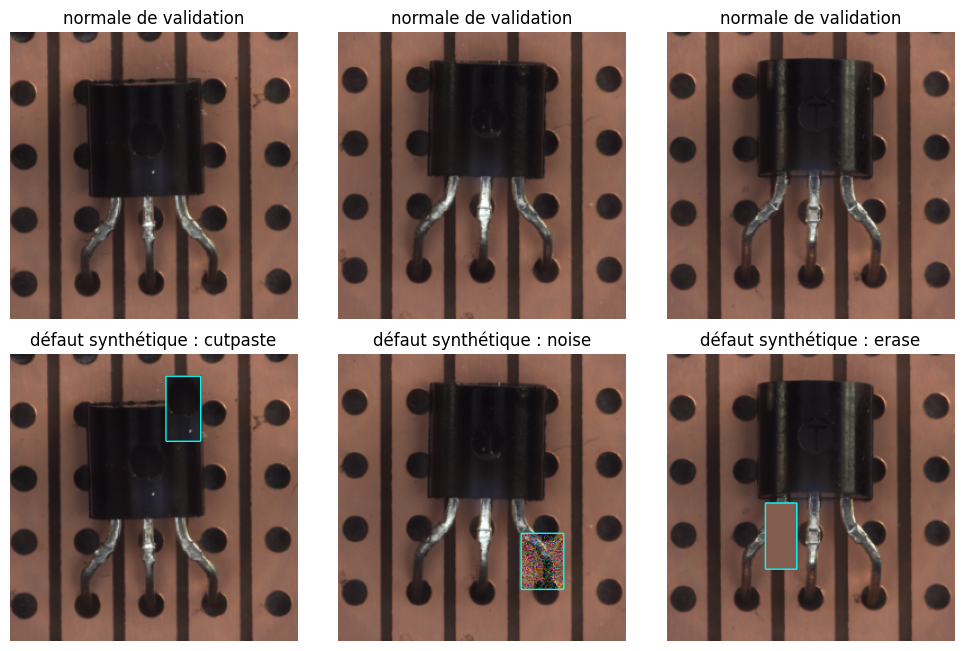

Paires normale / synthétique : 43 | {'cutpaste': 15, 'noise': 14, 'erase': 14}


In [3]:
import matplotlib.pyplot as plt


def make_synthetic(image: torch.Tensor, kind: str, rng: np.random.Generator):
    # image [3, H, W] dans [0, 1] -> (image défectueuse, masque [H, W] booléen)
    out = image.clone()
    _, height, width = image.shape
    h, w = int(rng.integers(24, 65)), int(rng.integers(24, 65))
    y = int(rng.integers(16, height - h - 16))
    x = int(rng.integers(16, width - w - 16))
    if kind == "cutpaste":
        sy = int(rng.integers(16, height - h - 16))
        sx = int(rng.integers(16, width - w - 16))
        patch = image[:, sy:sy + h, sx:sx + w] * float(rng.uniform(0.8, 1.2))
        out[:, y:y + h, x:x + w] = patch
    elif kind == "noise":
        noise = torch.from_numpy(rng.normal(0.0, 0.15, size=(3, h, w))).float()
        out[:, y:y + h, x:x + w] = image[:, y:y + h, x:x + w] + noise
    elif kind == "erase":
        border = torch.cat([image[:, :8, :].flatten(1), image[:, -8:, :].flatten(1)], dim=1)
        out[:, y:y + h, x:x + w] = border.mean(dim=1)[:, None, None]
    else:
        raise ValueError(kind)
    mask = torch.zeros(height, width, dtype=torch.bool)
    mask[y:y + h, x:x + w] = True
    return out.clamp(0.0, 1.0), mask


val_images = torch.stack([val_ds[i]["image"] for i in range(len(val_ds))])
synth_rng = np.random.default_rng(SELECTION["synthetic_seed"])
synth_kinds = [SELECTION["synthetic_types"][i % 3] for i in range(len(val_ds))]
synth_pairs = [make_synthetic(val_images[i], synth_kinds[i], synth_rng) for i in range(len(val_ds))]
synth_images = torch.stack([p[0] for p in synth_pairs])
assert not torch.equal(synth_images, val_images)

fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for col in range(3):
    axes[0, col].imshow(val_images[col].permute(1, 2, 0).numpy())
    axes[0, col].set_title("normale de validation")
    axes[1, col].imshow(synth_images[col].permute(1, 2, 0).numpy())
    axes[1, col].contour(synth_pairs[col][1].numpy(), levels=[0.5], colors="cyan", linewidths=1)
    axes[1, col].set_title(f"défaut synthétique : {synth_kinds[col]}")
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "synthetic_validation_examples.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Paires normale / synthétique :", len(val_images), "|", {k: synth_kinds.count(k) for k in set(synth_kinds)})

## Boucle d'entraînement (EXP-002 de Mouad, étendue)
Même boucle que l'EXP-002 : Adam, `ReduceLROnPlateau`, early stopping sur l'objectif de
validation. Ajouts : perte SSIM optionnelle (variante B), MSE de validation toujours
mesurée, et AUROC synthétique de validation toutes les 5 époques pour choisir le checkpoint.

In [4]:
import time

import pandas as pd
from sklearn.metrics import roc_auc_score

SCORING = CAEInferenceConfig(smoothing_sigma=EXPERIMENT["scoring"]["smoothing_sigma"],
                             score_method=EXPERIMENT["scoring"]["score_method"])


def gaussian_window(size: int, sigma: float, channels: int) -> torch.Tensor:
    coords = torch.arange(size, dtype=torch.float32) - (size - 1) / 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    window = (g[:, None] @ g[None, :])[None, None]
    return window.expand(channels, 1, size, size).contiguous()


SSIM_WINDOW = gaussian_window(11, 1.5, 3).to(DEVICE)


def ssim(x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    # SSIM moyen (Wang et al., 2004), fenêtre gaussienne 11x11, sigma 1.5, images dans [0, 1].
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    pad = SSIM_WINDOW.shape[-1] // 2
    mu_x = F.conv2d(x, SSIM_WINDOW, padding=pad, groups=3)
    mu_y = F.conv2d(y, SSIM_WINDOW, padding=pad, groups=3)
    sxx = F.conv2d(x * x, SSIM_WINDOW, padding=pad, groups=3) - mu_x ** 2
    syy = F.conv2d(y * y, SSIM_WINDOW, padding=pad, groups=3) - mu_y ** 2
    sxy = F.conv2d(x * y, SSIM_WINDOW, padding=pad, groups=3) - mu_x * mu_y
    num = (2 * mu_x * mu_y + c1) * (2 * sxy + c2)
    den = (mu_x ** 2 + mu_y ** 2 + c1) * (sxx + syy + c2)
    return (num / den).mean()


@torch.no_grad()
def score_images(model, images: torch.Tensor, batch: int = 16):
    # Scores et cartes avec EXACTEMENT le moteur de l'application (CAEInference).
    engine = CAEInference(model, CATEGORY, "cae_baseline_v1", SCORING)
    scores, maps = [], []
    for start in range(0, len(images), batch):
        for result in engine.predict_batch(images[start:start + batch]):
            scores.append(result.score)
            maps.append(result.anomaly_map)
    return np.asarray(scores, dtype=np.float64), torch.stack(maps)


def synthetic_auroc(model) -> float:
    normal_scores, _ = score_images(model, val_images)
    defect_scores, _ = score_images(model, synth_images)
    labels = np.r_[np.zeros(len(normal_scores)), np.ones(len(defect_scores))]
    return float(roc_auc_score(labels, np.r_[normal_scores, defect_scores]))


def train_variant(name: str, ssim_weight: float) -> dict:
    variant_dir = OUTPUT_DIR / f"variant_{name}"
    variant_dir.mkdir(parents=True, exist_ok=True)
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False

    model = ConvolutionalAutoencoder(CAE_CONFIG).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING["learning_rate"])
    sched = TRAINING["lr_scheduler"]
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=sched["factor"], patience=sched["patience"],
        threshold=sched["threshold"], threshold_mode="abs", min_lr=sched["min_lr"])
    stopping = TRAINING["early_stopping"]

    def run_epoch(loader, train: bool):
        model.train(train)
        totals = {"objective": 0.0, "mse": 0.0}
        count = 0
        with torch.set_grad_enabled(train):
            for batch in loader:
                images = batch["image"].to(DEVICE, non_blocking=True)
                recon = model(images)
                mse = F.mse_loss(recon, images)
                objective = mse + ssim_weight * (1 - ssim(recon, images)) if ssim_weight else mse
                if train:
                    optimizer.zero_grad(set_to_none=True)
                    objective.backward()
                    optimizer.step()
                totals["objective"] += objective.item() * images.size(0)
                totals["mse"] += mse.item() * images.size(0)
                count += images.size(0)
        return {k: v / count for k, v in totals.items()}

    history = []
    best = {"auroc": -1.0, "val_mse": float("inf"), "epoch": None}
    best_objective, stale, stop_reason = float("inf"), 0, "max_epochs"
    ckpt = variant_dir / "best_model.pt"
    start = time.time()
    max_epochs = TRAINING["max_epochs"]

    for epoch in range(1, max_epochs + 1):
        tr = run_epoch(train_loader, True)
        va = run_epoch(val_loader, False)
        if not all(np.isfinite(v) for v in (*tr.values(), *va.values())):
            raise RuntimeError(f"Perte non finie à l'époque {epoch}")
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step(va["objective"])

        auroc = None
        if epoch % SELECTION["eval_every_epochs"] == 0 or epoch == max_epochs:
            auroc = synthetic_auroc(model)
            better = auroc > best["auroc"] or (auroc == best["auroc"] and va["mse"] < best["val_mse"])
            if better:
                best = {"auroc": auroc, "val_mse": va["mse"], "epoch": epoch}
                torch.save(model.state_dict(), ckpt)

        if va["objective"] < best_objective - stopping["min_delta"]:
            best_objective, stale = va["objective"], 0
        else:
            stale += 1

        history.append({"epoch": epoch, "train_objective": tr["objective"], "train_mse": tr["mse"],
                        "val_objective": va["objective"], "val_mse": va["mse"],
                        "val_synthetic_auroc": auroc, "learning_rate": lr})
        if epoch == 1 or epoch % 10 == 0:
            shown = f"{auroc:.4f}" if auroc is not None else "  —   "
            print(f"[{name}] Époque {epoch:3d}/{max_epochs} | val MSE {va['mse']:.6f} | "
                  f"AUROC synth {shown} | meilleure {best['auroc']:.4f} (ép. {best['epoch']}) | "
                  f"LR {lr:.6f} | {time.time() - start:.0f} s")
        if stale >= stopping["patience"]:
            stop_reason = "early_stopping"
            print(f"[{name}] Early stopping à l'époque {epoch}")
            break

    if best["epoch"] is None:  # sécurité : au moins une évaluation
        best = {"auroc": synthetic_auroc(model), "val_mse": va["mse"], "epoch": epoch}
        torch.save(model.state_dict(), ckpt)

    history_df = pd.DataFrame(history)
    history_df.to_csv(variant_dir / "history.csv", index=False)
    summary = {"variant": name, "loss": EXPERIMENT["variants"][name]["loss"],
               "epochs_run": len(history), "stop_reason": stop_reason,
               "best_epoch": best["epoch"], "best_val_synthetic_auroc": best["auroc"],
               "val_mse_at_best": best["val_mse"],
               "min_val_mse": float(history_df["val_mse"].min()),
               "training_time_min": round((time.time() - start) / 60, 1),
               "checkpoint": str(ckpt.relative_to(OUTPUT_DIR))}
    print(f"[{name}] Terminé : meilleure AUROC synth {best['auroc']:.4f} à l'époque {best['epoch']} "
          f"({summary['training_time_min']} min, arrêt : {stop_reason})")
    return {"summary": summary, "history": history_df, "checkpoint": ckpt}

### Variante A — MSE (EXP-002 de Mouad)

In [5]:
RESULT_A = train_variant("A", EXPERIMENT["variants"]["A"]["ssim_weight"])

[A] Époque   1/300 | val MSE 0.029945 | AUROC synth   —    | meilleure -1.0000 (ép. None) | LR 0.001000 | 14 s
[A] Époque  10/300 | val MSE 0.003471 | AUROC synth 0.4959 | meilleure 0.5019 (ép. 5) | LR 0.001000 | 79 s
[A] Époque  20/300 | val MSE 0.001974 | AUROC synth 0.5043 | meilleure 0.5043 (ép. 20) | LR 0.001000 | 150 s
[A] Époque  30/300 | val MSE 0.001406 | AUROC synth 0.5130 | meilleure 0.5130 (ép. 30) | LR 0.001000 | 220 s
[A] Époque  40/300 | val MSE 0.001068 | AUROC synth 0.5254 | meilleure 0.5254 (ép. 40) | LR 0.001000 | 291 s
[A] Époque  50/300 | val MSE 0.000964 | AUROC synth 0.5349 | meilleure 0.5349 (ép. 50) | LR 0.001000 | 362 s
[A] Époque  60/300 | val MSE 0.000820 | AUROC synth 0.5544 | meilleure 0.5544 (ép. 60) | LR 0.001000 | 432 s
[A] Époque  70/300 | val MSE 0.000762 | AUROC synth 0.5590 | meilleure 0.5608 (ép. 65) | LR 0.001000 | 503 s
[A] Époque  80/300 | val MSE 0.000708 | AUROC synth 0.5792 | meilleure 0.5792 (ép. 80) | LR 0.001000 | 573 s
[A] Époque  90/300 

### Variante B — MSE + SSIM

In [6]:
RESULT_B = train_variant("B", EXPERIMENT["variants"]["B"]["ssim_weight"])

[B] Époque   1/300 | val MSE 0.060976 | AUROC synth   —    | meilleure -1.0000 (ép. None) | LR 0.001000 | 7 s
[B] Époque  10/300 | val MSE 0.004912 | AUROC synth 0.5062 | meilleure 0.5062 (ép. 10) | LR 0.001000 | 70 s
[B] Époque  20/300 | val MSE 0.002027 | AUROC synth 0.5041 | meilleure 0.5081 (ép. 15) | LR 0.001000 | 141 s
[B] Époque  30/300 | val MSE 0.001281 | AUROC synth 0.5054 | meilleure 0.5092 (ép. 25) | LR 0.001000 | 211 s
[B] Époque  40/300 | val MSE 0.000824 | AUROC synth 0.5254 | meilleure 0.5254 (ép. 40) | LR 0.001000 | 281 s
[B] Époque  50/300 | val MSE 0.000676 | AUROC synth 0.5625 | meilleure 0.5625 (ép. 50) | LR 0.001000 | 352 s
[B] Époque  60/300 | val MSE 0.000660 | AUROC synth 0.5836 | meilleure 0.5836 (ép. 60) | LR 0.001000 | 423 s
[B] Époque  70/300 | val MSE 0.000680 | AUROC synth 0.5933 | meilleure 0.5933 (ép. 70) | LR 0.001000 | 493 s
[B] Époque  80/300 | val MSE 0.000587 | AUROC synth 0.6174 | meilleure 0.6201 (ép. 75) | LR 0.001000 | 564 s
[B] Époque  90/300 

## Choix de la variante (Validation uniquement)
Règle fixée à l'avance : plus haute AUROC synthétique de validation ; égalité → plus faible
MSE de validation. Le checkpoint retenu devient `cae_model.pt` (poids seuls, même format qu'EXP-001).

                           loss  epochs_run stop_reason  best_epoch  best_val_synthetic_auroc  val_mse_at_best  training_time_min
variant                                                                                                                          
A                           MSE         300  max_epochs         240                  0.693348         0.000416               35.2
B        MSE + 0.5 * (1 - SSIM)         300  max_epochs         275                  0.686047         0.000377               35.3

Variante retenue sur la validation : A (MSE)
Checkpoint final : cae_model.pt (3.4 Mo)
SHA-256          : b7c06c22b1f53878a91f62eddf2cfb7f3311f785a98119b21266b722207da132


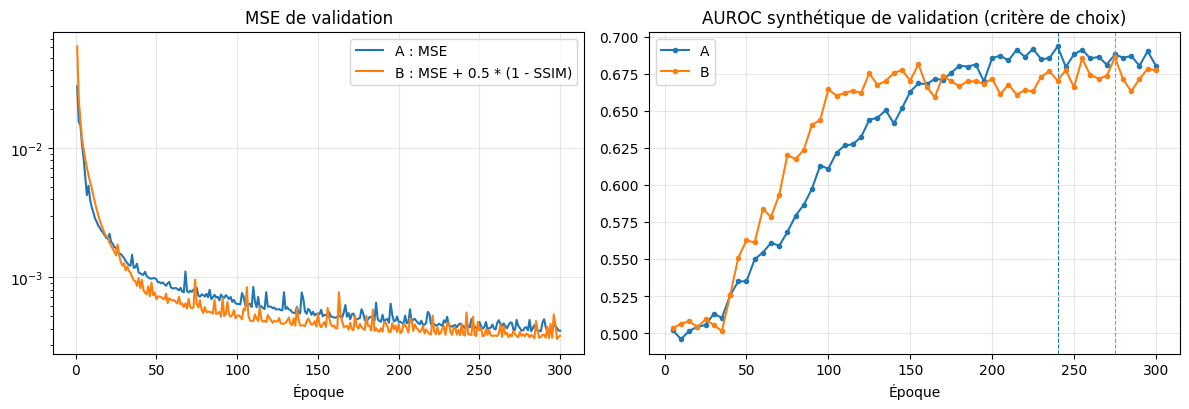

In [7]:
RESULTS = {"A": RESULT_A, "B": RESULT_B}
selection_table = pd.DataFrame([r["summary"] for r in RESULTS.values()]).set_index("variant")
display_cols = ["loss", "epochs_run", "stop_reason", "best_epoch", "best_val_synthetic_auroc",
                "val_mse_at_best", "training_time_min"]
print(selection_table[display_cols].to_string())

CHOSEN = max(RESULTS, key=lambda k: (RESULTS[k]["summary"]["best_val_synthetic_auroc"],
                                     -RESULTS[k]["summary"]["val_mse_at_best"]))
print(f"\nVariante retenue sur la validation : {CHOSEN} ({RESULTS[CHOSEN]['summary']['loss']})")

final_model = ConvolutionalAutoencoder(CAE_CONFIG).to(DEVICE)
final_model.load_state_dict(torch.load(RESULTS[CHOSEN]["checkpoint"], map_location=DEVICE, weights_only=True))
final_model.eval()
FINAL_CHECKPOINT = OUTPUT_DIR / "cae_model.pt"
torch.save(final_model.state_dict(), FINAL_CHECKPOINT)
FINAL_SHA256 = sha256_of(FINAL_CHECKPOINT)
print("Checkpoint final :", FINAL_CHECKPOINT.name, f"({FINAL_CHECKPOINT.stat().st_size / 1e6:.1f} Mo)")
print("SHA-256          :", FINAL_SHA256)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for key, result in RESULTS.items():
    h = result["history"]
    axes[0].plot(h["epoch"], h["val_mse"], label=f"{key} : {result['summary']['loss']}")
    pts = h.dropna(subset=["val_synthetic_auroc"])
    axes[1].plot(pts["epoch"], pts["val_synthetic_auroc"], marker="o", markersize=3, label=key)
    axes[1].axvline(result["summary"]["best_epoch"], linestyle="--", linewidth=0.8,
                    color=axes[1].lines[-1].get_color())
axes[0].set_yscale("log"); axes[0].set_title("MSE de validation"); axes[0].set_xlabel("Époque")
axes[1].set_title("AUROC synthétique de validation (critère de choix)"); axes[1].set_xlabel("Époque")
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## Calibration du seuil (protocole US-05-02)
Quantile 0,95 linéaire des scores des **43 normales de validation**, règle `score > seuil`.

In [8]:
val_scores, _ = score_images(final_model, val_images)
THRESHOLD = float(np.quantile(val_scores, 0.95, method="linear"))
pd.DataFrame({"image_path": [s["image_path"] for s in val_ds.samples], "label": 0,
              "score": val_scores}).to_csv(OUTPUT_DIR / "validation_scores.csv", index=False)
calibration = {"experiment_id": EXPERIMENT_ID, "variant": CHOSEN, "n_val_normals": int(len(val_scores)),
               "policy": EXPERIMENT["calibration"], "threshold": THRESHOLD,
               "threshold_hex": THRESHOLD.hex(),
               "val_score_stats": {"min": float(val_scores.min()), "median": float(np.median(val_scores)),
                                   "max": float(val_scores.max())},
               "checkpoint_sha256": FINAL_SHA256}
(OUTPUT_DIR / "calibration.json").write_text(json.dumps(calibration, indent=2), encoding="utf-8")
print(f"Seuil EXP-003 : {THRESHOLD:.6f}  (EXP-001 : {EXP001_REFERENCE['threshold']:.6f})")
print(f"Normales de validation au-dessus du seuil : {(val_scores > THRESHOLD).sum()} / {len(val_scores)}")

Seuil EXP-003 : 0.018426  (EXP-001 : 0.027365)
Normales de validation au-dessus du seuil : 3 / 43


## Évaluation finale sur le test officiel (une seule fois)
Le test est chargé **maintenant**, après tous les choix. Si le checkpoint EXP-001 est ajouté
en input Kaggle (par exemple le dataset `industrialdefect-us0502-missing-checkpoints`),
il est réévalué avec exactement le même code, pour une comparaison à l'identique.

In [9]:
test_ds = MVTecDataset(DATASET_ROOT, MANIFEST, CATEGORY, "test", transform)
assert len(test_ds) == 100, len(test_ds)
test_items = [test_ds[i] for i in range(len(test_ds))]
test_images = torch.stack([t["image"] for t in test_items])
test_masks = torch.stack([t["mask"][0] for t in test_items]).numpy().astype(np.uint8)
test_labels = np.asarray([t["label"] for t in test_items])
test_types = [t["defect_type"] or "good" for t in test_items]


def evaluate(model, threshold: float, tag: str) -> dict:
    scores, maps = score_images(model, test_images)
    metrics = compute_image_metrics(test_labels, scores, threshold)
    metrics["pixel_auroc"] = float(compute_pixel_auroc(test_masks, maps.numpy()))
    preds = (scores > threshold).astype(int)
    per_type = {}
    for kind in sorted(set(test_types)):
        idx = [i for i, t in enumerate(test_types) if t == kind]
        if kind == "good":
            per_type[kind] = {"n": len(idx), "fausses_alertes": int(preds[idx].sum())}
        else:
            per_type[kind] = {"n": len(idx), "detectes": int(preds[idx].sum()),
                              "recall": float(preds[idx].mean())}
    metrics["per_defect_type"] = per_type
    predictions = pd.DataFrame({"image_path": [t["image_path"] for t in test_items], "label": test_labels,
                                "defect_type": test_types, "score": scores, "threshold": threshold,
                                "prediction": preds})
    print(f"[{tag}] AUROC image {metrics['image_auroc']:.4f} | recall {metrics['recall']:.3f} | "
          f"precision {metrics['precision']:.3f} | F1 {metrics['f1']:.3f} | AUROC pixel {metrics['pixel_auroc']:.4f}")
    return {"metrics": metrics, "predictions": predictions, "scores": scores, "maps": maps}


EVAL_003 = evaluate(final_model, THRESHOLD, EXPERIMENT_ID)
EVAL_003["predictions"].to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

# Réévaluation optionnelle d'EXP-001 avec le même code (si son checkpoint est en input).
EVAL_001 = None
search_root = Path(os.environ.get("IDL_EXP001_DIR", "/kaggle/input"))
for candidate in sorted(search_root.rglob("*.pt")) if search_root.exists() else []:
    if candidate.stat().st_size < 10_000_000 and sha256_of(candidate) == EXP001_REFERENCE["checkpoint_sha256"]:
        engine_001 = CAEInference.from_checkpoint(CATEGORY, REPO_DIR / EXPERIMENT["model_config"],
                                                  candidate, DEVICE, SCORING)
        model_001 = engine_001.model
        val_001, _ = score_images(model_001, val_images)
        threshold_001 = float(np.quantile(val_001, 0.95, method="linear"))
        print(f"EXP-001 trouvé : {candidate} | seuil recalculé {threshold_001:.6f} "
              f"(archivé {EXP001_REFERENCE['threshold']:.6f}) | AUROC synth {synthetic_auroc(model_001):.4f}")
        EVAL_001 = evaluate(model_001, threshold_001, "EXP-001 (réévalué)")
        break
else:
    print("Checkpoint EXP-001 non fourni en input : comparaison avec les valeurs archivées US-05-03.")

[EXP-003] AUROC image 0.6121 | recall 0.225 | precision 0.900 | F1 0.360 | AUROC pixel 0.6636
Checkpoint EXP-001 non fourni en input : comparaison avec les valeurs archivées US-05-03.


             EXP-001 (archivé US-05-03)  EXP-003 (variante A)
Image-AUROC                      0.5858                0.6121
Recall                           0.1500                0.2250
Precision                        1.0000                0.9000
F1                               0.2609                0.3600
Pixel-AUROC                      0.6360                0.6636

Défauts détectés : EXP-001 6/40  →  EXP-003 9/40
Fausses alertes  : EXP-001 0/60  →  EXP-003 1/60

Par type de défaut :
  bent_lead     {'n': 10, 'detectes': 3, 'recall': 0.3}
  cut_lead      {'n': 10, 'detectes': 1, 'recall': 0.1}
  damaged_case  {'n': 10, 'detectes': 0, 'recall': 0.0}
  good          {'n': 60, 'fausses_alertes': 1}
  misplaced     {'n': 10, 'detectes': 5, 'recall': 0.5}


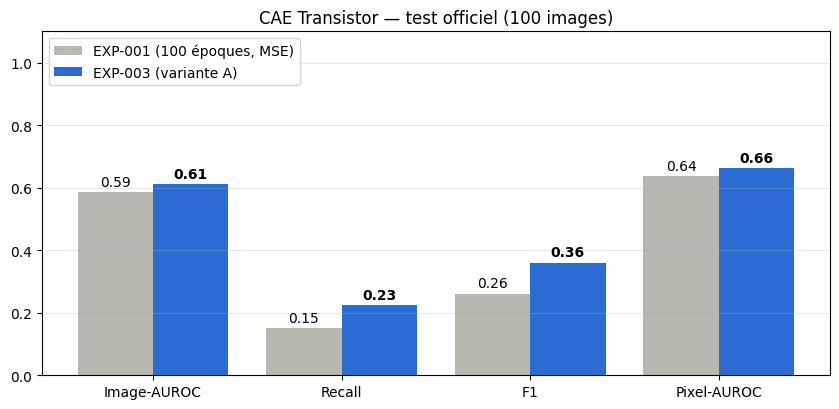

In [10]:
m3 = EVAL_003["metrics"]
rows = [("Image-AUROC", "image_auroc"), ("Recall", "recall"), ("Precision", "precision"),
        ("F1", "f1"), ("Pixel-AUROC", "pixel_auroc")]
comparison = pd.DataFrame({
    "EXP-001 (archivé US-05-03)": [EXP001_REFERENCE[k] for _, k in rows],
    **({"EXP-001 (réévalué ici)": [EVAL_001["metrics"][k] for _, k in rows]} if EVAL_001 else {}),
    f"{EXPERIMENT_ID} (variante {CHOSEN})": [m3[k] for _, k in rows],
}, index=[label for label, _ in rows])
print(comparison.round(4).to_string())
print(f"\nDéfauts détectés : EXP-001 {EXP001_REFERENCE['tp']}/40  →  {EXPERIMENT_ID} {m3['tp']}/40")
print(f"Fausses alertes  : EXP-001 {EXP001_REFERENCE['fp']}/60  →  {EXPERIMENT_ID} {m3['fp']}/60")
print("\nPar type de défaut :")
for kind, values in m3["per_defect_type"].items():
    print(f"  {kind:13s} {values}")

metrics_doc = {"experiment_id": EXPERIMENT_ID, "variant": CHOSEN, "category": CATEGORY,
               "threshold": THRESHOLD, "checkpoint_sha256": FINAL_SHA256, "test": m3,
               "exp001_reference": EXP001_REFERENCE,
               "exp001_reevaluated": EVAL_001["metrics"] if EVAL_001 else None}
(OUTPUT_DIR / "test_metrics.json").write_text(json.dumps(metrics_doc, indent=2, ensure_ascii=False),
                                               encoding="utf-8")

# Figure de synthèse pour la présentation.
labels_fig = ["Image-AUROC", "Recall", "F1", "Pixel-AUROC"]
keys_fig = ["image_auroc", "recall", "f1", "pixel_auroc"]
x = np.arange(len(labels_fig))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(x - 0.2, [EXP001_REFERENCE[k] for k in keys_fig], 0.4, label="EXP-001 (100 époques, MSE)", color="#b8b8b0")
ax.bar(x + 0.2, [m3[k] for k in keys_fig], 0.4, label=f"{EXPERIMENT_ID} (variante {CHOSEN})", color="#2b6cd4")
for i, k in enumerate(keys_fig):
    ax.text(i - 0.2, EXP001_REFERENCE[k] + 0.02, f"{EXP001_REFERENCE[k]:.2f}", ha="center")
    ax.text(i + 0.2, m3[k] + 0.02, f"{m3[k]:.2f}", ha="center", fontweight="bold")
ax.set_xticks(x, labels_fig); ax.set_ylim(0, 1.1); ax.set_title("CAE Transistor — test officiel (100 images)")
ax.legend(loc="upper left"); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "exp001_vs_exp003.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## Exemples sur le test (un par type de défaut)
Image, reconstruction, carte d'anomalie superposée (contour cyan = masque réel), avec score,
seuil et décision. L'échelle de couleur est propre à chaque carte : elle ne change ni le score
ni la décision.

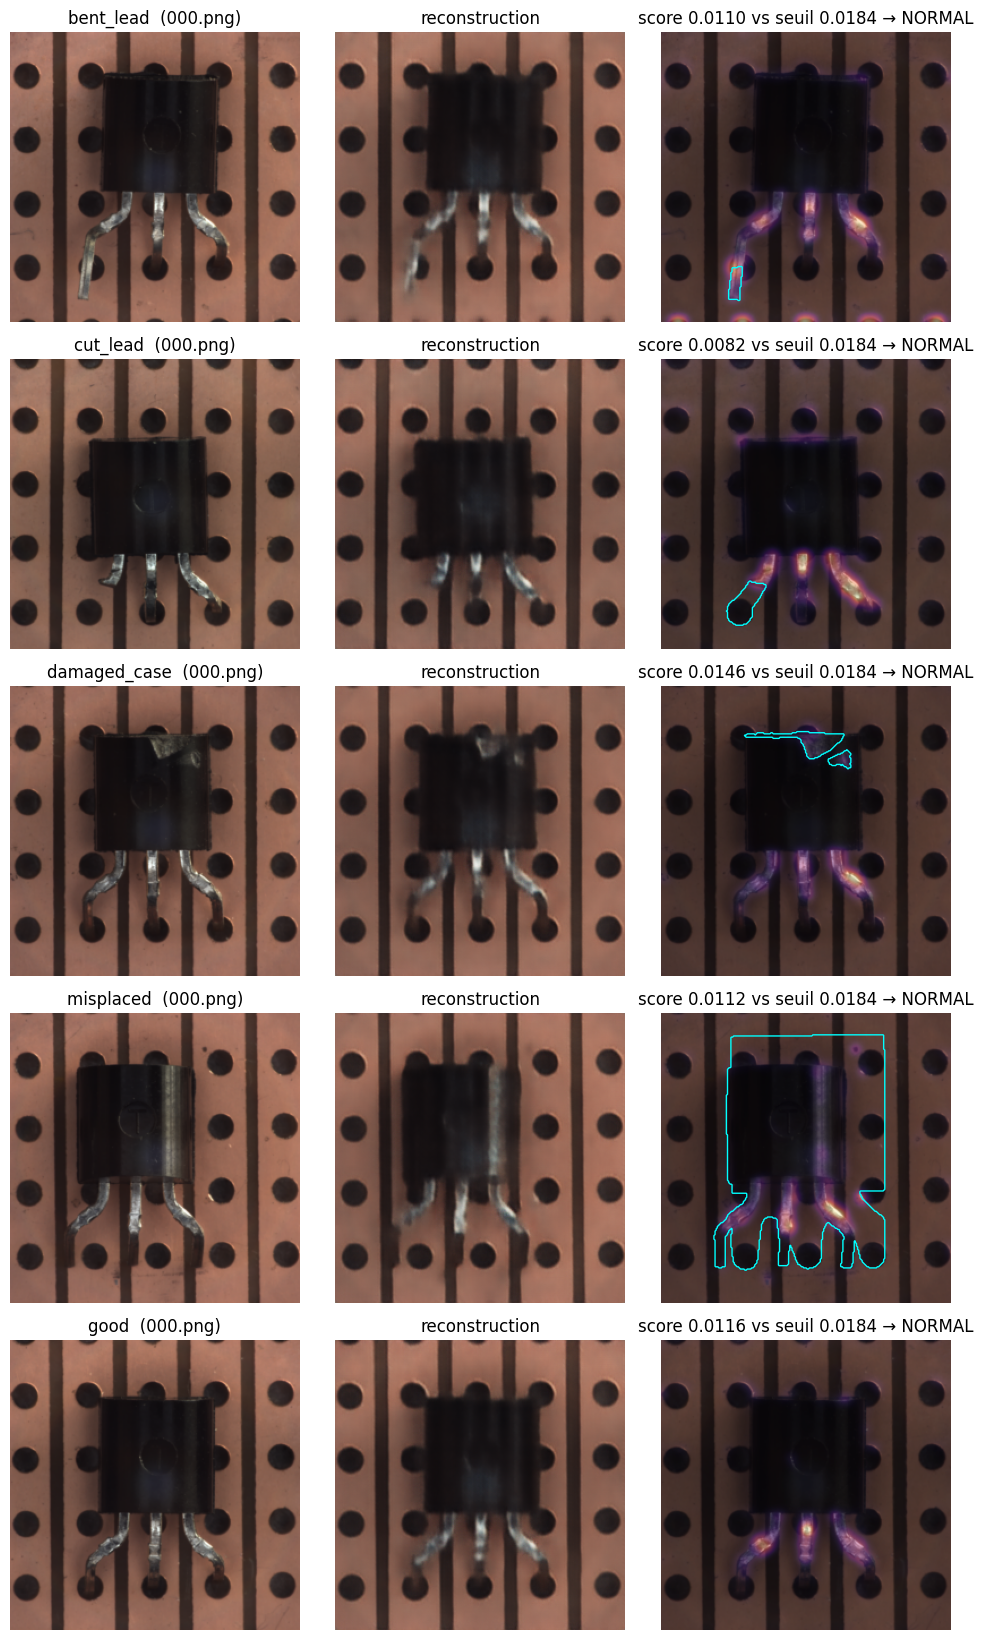

In [11]:
kinds = [k for k in ["bent_lead", "cut_lead", "damaged_case", "misplaced", "good"] if k in test_types]
picked = [test_types.index(k) for k in kinds]
engine = CAEInference(final_model, CATEGORY, "cae_baseline_v1", SCORING)
fig, axes = plt.subplots(len(picked), 3, figsize=(10, 3.3 * len(picked)))
axes = np.atleast_2d(axes)
for row, idx in enumerate(picked):
    result = engine.predict_batch(test_images[idx:idx + 1])[0]
    image = test_images[idx].permute(1, 2, 0).numpy()
    decision = "SUSPECT" if result.score > THRESHOLD else "NORMAL"
    axes[row, 0].imshow(image); axes[row, 0].set_title(f"{test_types[idx]}  ({test_items[idx]['image_path'].split('/')[-1]})")
    axes[row, 1].imshow(result.reconstruction.permute(1, 2, 0).numpy()); axes[row, 1].set_title("reconstruction")
    axes[row, 2].imshow(image)
    axes[row, 2].imshow(result.anomaly_map.numpy(), cmap="magma", alpha=0.45)
    if test_masks[idx].any():
        axes[row, 2].contour(test_masks[idx], levels=[0.5], colors="cyan", linewidths=1)
    axes[row, 2].set_title(f"score {result.score:.4f} vs seuil {THRESHOLD:.4f} → {decision}")
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_examples.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)

## Informations d'exécution et fichiers produits

In [12]:
import platform
from datetime import datetime, timezone

run_info = {
    "experiment_id": EXPERIMENT_ID,
    "category": CATEGORY,
    "executed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "code": {"repo": REPO_URL, "branch": REPO_BRANCH, "git_commit": GIT_COMMIT,
             "notebook": "notebooks/06-cae-transistor-exp003.ipynb"},
    "environment": {"platform": "local dry run" if DRY_RUN else "Kaggle",
                    "python_version": sys.version.split()[0], "torch_version": torch.__version__,
                    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
                    "os": platform.platform()},
    "data": {"dataset": "MVTec AD", "dataset_version": "ipythonx/mvtec-ad, Version 2",
             "split_manifest": EXPERIMENT["manifest"], "manifest_sha256": sha256_of(MANIFEST),
             "train_images": len(train_ds), "val_images": len(val_ds), "test_images": len(test_ds),
             "test_used_for_selection": False},
    "experiment": EXPERIMENT,
    "variants": {k: r["summary"] for k, r in RESULTS.items()},
    "chosen_variant": CHOSEN,
    "final_checkpoint": {"file": "cae_model.pt", "sha256": FINAL_SHA256, "format": "state_dict"},
    "threshold": THRESHOLD,
    "test_metrics": {k: m3[k] for k in ("image_auroc", "precision", "recall", "f1", "pixel_auroc",
                                         "tp", "tn", "fp", "fn")},
}
(OUTPUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"===== CAE TRANSISTOR {EXPERIMENT_ID} =====")
print(f"Variante retenue : {CHOSEN} ({EXPERIMENT['variants'][CHOSEN]['loss']})")
print(f"Seuil            : {THRESHOLD:.6f}")
print(f"Test             : AUROC {m3['image_auroc']:.3f} | recall {m3['recall']:.3f} | F1 {m3['f1']:.3f} "
      f"(EXP-001 : AUROC 0.586 | recall 0.150 | F1 0.261)")
print("\nFichiers dans l'Output :")
for f in sorted(p for p in OUTPUT_DIR.rglob("*") if p.is_file()):
    print(f"  {str(f.relative_to(OUTPUT_DIR)):40s} {f.stat().st_size / 1e3:9.1f} Ko")

===== CAE TRANSISTOR EXP-003 =====
Variante retenue : A (MSE)
Seuil            : 0.018426
Test             : AUROC 0.612 | recall 0.225 | F1 0.360 (EXP-001 : AUROC 0.586 | recall 0.150 | F1 0.261)

Fichiers dans l'Output :
  cae_model.pt                                3428.8 Ko
  calibration.json                               0.5 Ko
  exp001_vs_exp003.png                          48.8 Ko
  run_info.json                                  4.0 Ko
  synthetic_validation_examples.png            772.9 Ko
  test_examples.png                           1986.0 Ko
  test_metrics.json                              1.5 Ko
  test_predictions.csv                           8.5 Ko
  training_curves.png                          128.1 Ko
  validation_scores.csv                          2.3 Ko
  variant_A/best_model.pt                     3428.9 Ko
  variant_A/history.csv                         30.8 Ko
  variant_B/best_model.pt                     3428.9 Ko
  variant_B/history.csv                         3